In [2]:
%pip install xgboost shap


  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
  Using cached shap-0.52.0-cp312-abi3-win_amd64.whl.metadata (26 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Using cached shap-0.52.0-cp312-abi3-win_amd64.whl (499 kB)
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)

   ------------- -------------------------- 1/3 [xgboost]
   ------------- -------------------------- 1/3 [xgboost]
   ------------- -------------------------- 1/3 [xgboost]
   ------------- -------------------------- 1/3 [xgboost]
   ------------- -------------------------- 1/3 [xgboost]
   ------------- -------------------------- 1/3 [xgboost]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -

In [4]:
import sys, os, joblib, pandas as pd, numpy as np, matplotlib.pyplot as plt
P = r"C:\Users\harsh\Downloads\churn-project (1)\churn-project"
sys.path.append(os.path.join(P, "src"))
from preprocess import load_data, split_data, build_preprocessor
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay)

df = load_data(os.path.join(P, "data", "churn_clean.csv"))
X_train, X_test, y_train, y_test = split_data(df)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def make(model):
    return Pipeline([("prep", build_preprocessor(scale=False)), ("model", model)])

In [5]:
searches = {
    "Random Forest (tuned)": (make(RandomForestClassifier(random_state=42)), {
        "model__n_estimators": [200, 300, 500], "model__max_depth": [4, 6, 8, 10],
        "model__min_samples_leaf": [5, 10, 20], "model__max_features": ["sqrt", 0.5]}),
    "Gradient Boosting": (make(GradientBoostingClassifier(random_state=42)), {
        "model__n_estimators": [100, 200, 300], "model__max_depth": [2, 3, 4],
        "model__learning_rate": [0.03, 0.05, 0.1], "model__subsample": [0.7, 0.8, 1.0]}),
    "XGBoost": (make(XGBClassifier(random_state=42, eval_metric="logloss", n_jobs=1)), {
        "model__n_estimators": [100, 200, 300, 500], "model__max_depth": [2, 3, 4, 5],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.1], "model__subsample": [0.7, 0.8, 1.0],
        "model__colsample_bytree": [0.7, 0.85, 1.0]}),
}
tuned = {}
for name, (pipe, grid) in searches.items():
    s = RandomizedSearchCV(pipe, grid, n_iter=15, scoring="roc_auc", cv=cv, random_state=42, n_jobs=-1)
    s.fit(X_train, y_train)
    tuned[name] = s
    print(name, "| CV AUC:", round(s.best_score_, 3), "|", s.best_params_)

Random Forest (tuned) | CV AUC: 0.858 | {'model__n_estimators': 500, 'model__min_samples_leaf': 10, 'model__max_features': 0.5, 'model__max_depth': 8}
Gradient Boosting | CV AUC: 0.863 | {'model__subsample': 0.8, 'model__n_estimators': 200, 'model__max_depth': 4, 'model__learning_rate': 0.03}
XGBoost | CV AUC: 0.864 | {'model__subsample': 0.8, 'model__n_estimators': 300, 'model__max_depth': 3, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.85}


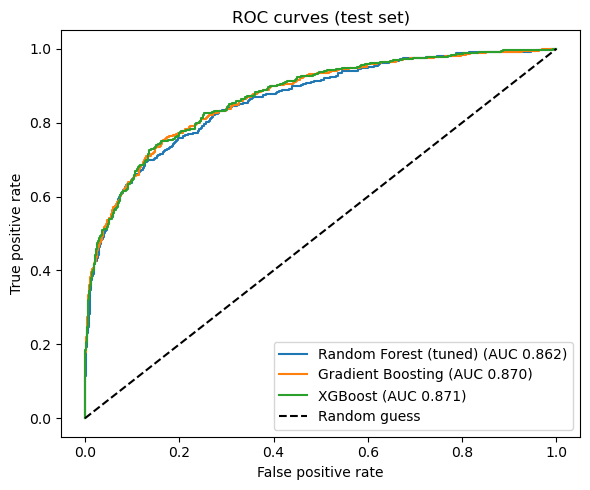

,Accuracy,Precision,Recall,F1,ROC-AUC,CV AUC
Model,,,,,,
Logistic Regression,0.808,0.583,0.189,0.286,0.774,0.762
Logistic Regression (balanced),0.714,0.388,0.708,0.501,0.777,0.765
Decision Tree,0.858,0.796,0.403,0.535,0.844,0.827
Random Forest,0.863,0.767,0.469,0.582,0.851,0.844
Random Forest (tuned),0.865,0.791,0.457,0.579,0.862,0.858
Gradient Boosting,0.866,0.782,0.477,0.592,0.870,0.863
XGBoost,0.872,0.805,0.486,0.606,0.871,0.864


In [6]:
rows = []
for name, s in tuned.items():
    proba = s.predict_proba(X_test)[:, 1]; pred = (proba >= 0.5).astype(int)
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred, zero_division=0),
                 "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, proba), "CV AUC": s.best_score_})
new = pd.DataFrame(rows).set_index("Model")
old = pd.read_csv(os.path.join(P, "reports", "day4_results.csv"), index_col="Model")
old = old.rename(columns={"ROC-AUC (test)": "ROC-AUC", "CV AUC mean": "CV AUC"})[new.columns]
comparison = pd.concat([old, new]).round(3)
comparison.to_csv(os.path.join(P, "reports", "day5_comparison.csv"))

plt.figure(figsize=(6, 5))
for name, s in tuned.items():
    p = s.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curves (test set)")
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(P, "reports", "figures", "14_roc_curves.png"), dpi=150)
plt.show()
comparison

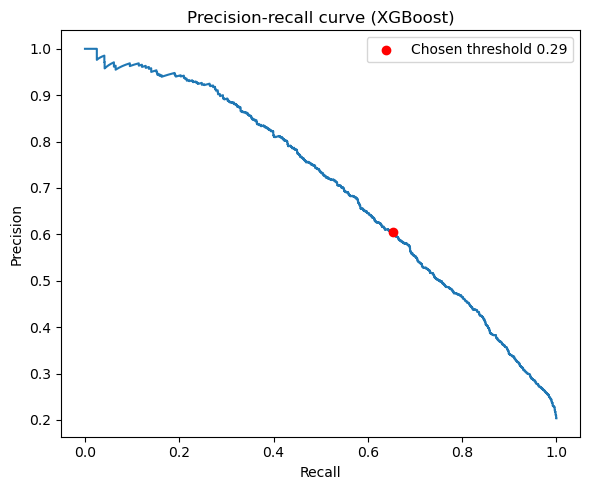

Default 0.5: precision 0.805, recall 0.486, F1 0.606
Chosen 0.29: precision 0.607, recall 0.676, F1 0.640


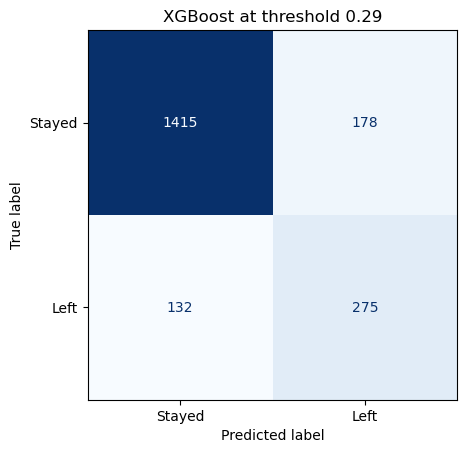

Saved final model: XGBoost | threshold 0.29


In [7]:
best_name = max(tuned, key=lambda k: tuned[k].best_score_)
final = tuned[best_name].best_estimator_
oof = cross_val_predict(final, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
i = int(np.argmax(f1s[:-1])); threshold = float(thr[i])

plt.figure(figsize=(6, 5))
plt.plot(rec, prec); plt.scatter(rec[i], prec[i], color="red", zorder=3, label=f"Chosen threshold {threshold:.2f}")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title(f"Precision-recall curve ({best_name})")
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(P, "reports", "figures", "15_precision_recall.png"), dpi=150)
plt.show()

proba = final.predict_proba(X_test)[:, 1]
for label, t in [("Default 0.5", 0.5), (f"Chosen {threshold:.2f}", threshold)]:
    pred = (proba >= t).astype(int)
    print(f"{label}: precision {precision_score(y_test, pred, zero_division=0):.3f}, recall {recall_score(y_test, pred):.3f}, F1 {f1_score(y_test, pred):.3f}")

pred = (proba >= threshold).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Stayed", "Left"]).plot(cmap="Blues", colorbar=False)
plt.title(f"{best_name} at threshold {threshold:.2f}")
plt.savefig(os.path.join(P, "reports", "figures", "16_final_confusion_matrix.png"), dpi=150)
plt.show()

joblib.dump({"pipeline": final, "threshold": threshold, "model_name": best_name},
            os.path.join(P, "models", "final_model.joblib"))
print("Saved final model:", best_name, "| threshold", round(threshold, 3))